# Computational Methods in Simulation (CMIS) Week 7
This notebook is intended to support your learning process. It contains exercises that help you to understand the material. 

This week is based on Slides 21 - follow the detailed instructions in order to build your own simulator:

* Hints: You might want to re-visit your FEM and FVM code pieces and reuse subparts of them for this larger project. The meshing week might prove useful for creating your own test cases to play with.

* Derive theory of how to create your own FVM simulator for simulating dynamic hyperelastic materials using a Saint-Vernant-Kirchoff model and a semi-implicit time-stepping scheme.
* Design experiments for verification and validation of your own simulator
* Present results of your experiments and discuss your findings
* If time is available try and extend the simulator to use adaptive or higher order time-stepping
* If time is available try and extend the simulator to use other types of material models
* If time is available try and extend the simulator to have dynamic boundary conditions to model "contact" when objects move around.

## Important Remark

* Do not be too agressive in terms of too large time-step size, too stiff materials and too large gravity. The semi-explicit nature of this overall method is quite sensitive, so use soft materials, almost no gravity and very small time-steps is recommended for prototyping and initial implementation. Once, it has been verified that code works, one can crank up values as close to reality as possible.

## Detailed Expected Learning Objectives of this Week

* Combine and show all skills learned through out the course.
* Design interesting and relevant experiments for verification and validation.
* Successfully create and discuss experimental results.
* Demonstrate ability to scientific discuss and reflect on the simulator.

In [1]:
%matplotlib widget

In [2]:
import igl
import meshplot as mp
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import matplotlib as mtp
from mpl_toolkits import mplot3d
import matplotlib.animation as animation
from IPython.display import HTML
import wildmeshing as wm

# Handling Mesh Geometry Information
In this week we may be able to resue material from previous weeks. In particular the beam mesh genreation function will be useful to us.

However, we make one important slight change to this mesh generation function to avoid ear-triangles when we ask it to generate an even number of horitonal and vertical nodes.

Ear triangles form a degenerate control volume and we do not like them for this reason. The most easy fix is to make sure we never generate ear-triangle in the first place.

In [3]:
def vec2(x,y):
    return np.array([x, y],dtype=np.float64)


def hat(p):
    return vec2(-p[1], p[0])


def compute_triangle_areas(V,T):
    E = len(T) # Total number of triangles in the mesh
    A = np.zeros((E,),dtype=np.float64)
    for e in range(E):
        # Get triangle indices
        i = T[e,0]
        j = T[e,1]
        k = T[e,2]
        # Get triangle coordinates
        xi = V[i,0]
        xj = V[j,0]
        xk = V[k,0]
        yi = V[i,1]
        yj = V[j,1]
        yk = V[k,1]    
        
        dx1 = xk - xj
        dy1 = yk - yj
        dx2 = xi - xj
        dy2 = yi - yj

        A[e] =  (dx1*dy2 - dx2*dy1 ) / 2.0

        if A[e] < 0:
            print(f'Triangle number: {e} has area {A[e]}')

    return A


def make_beam_mesh(width, height, shape):
    x0 = -width/2.0
    y0 = -height/2.0
    I  = shape[0]
    J  = shape[1]
    dx = width/float(I)
    dy = height/float(J)
    V = np.zeros(((I+1)*(J+1),2),dtype=np.float64)
    for j in range(J+1):
        for i in range(I+1):
            k = i + j*(I+1)
            V[k,0] = x0 + i*dx
            V[k,1] = y0 + j*dy
    T = np.zeros((2*I*J,3),dtype=np.int32)
    for j in range(J):
        for i in range(I):
            k00 = (i  ) + (j  )*(I+1)
            k01 = (i+1) + (j  )*(I+1)
            k10 = (i  ) + (j+1)*(I+1)
            k11 = (i+1) + (j+1)*(I+1)
            e = 2*(i + j*I)
            if (i+j+1)%2:
                T[e,  :] = (k00,k01,k11)
                T[e+1,:] = (k00,k11,k10)
            else:
                T[e,  :] = (k10,k00,k01)
                T[e+1,:] = (k10,k01,k11)                    
    return V, T

def make_circle_mesh(radius, segments):
    K = segments
    X = np.array([ radius*np.cos(2*np.pi*k/K) for k in range(K)])
    Y = np.array([ radius*np.sin(2*np.pi*k/K) for k in range(K)])
    P = np.zeros((K,2))
    P[:,0] = X
    P[:,1] = Y
    L = np.array([(k,(k+1)%K) for k in range(K)],dtype=np.int32)
    V, T, _, _ = wm.triangulate_data(P, L, cut_outside=True)
    return (V, T)

Later we will need to build a data structure for our control volumes. To create the control volumes we need to be able to query the mesh about connectivity information and geometric information as well. That is things like all triangles that share the same vertex or the outward unit normals of a triangle and so on.

To make this easy we provide a MeshInfo class that encapsulates simple libigl functionality into a more human readiable interface.

It is a great help to know how to "jump" around neighbors in a mesh data structure. We encourage therefore that students spend a bit of time getting into how this works so they can extend and customize their data structures as they need to with little effort.

In [4]:
class MeshInfo:
    
    def __init__(self, V, T):        
        self.A = compute_triangle_areas(V,T)
        if np.any(np.where(self.A<=0)):
            raise ValueError('Triangle with negative orientation exist.')
        bc = igl.barycenter(V,T)
        E = igl.edges(T)
        TT, _ = igl.triangle_triangle_adjacency(T)
        VT, NI = igl.vertex_triangle_adjacency(T, len(V))
        VV = igl.adjacency_list(T)
        self.V = V    # Vertices
        self.T = T    # Triangles
        self.E = E    # Edges
        self.TT = TT  # Triangle neighbors of triangles
        self.VT = VT  # Triangle neighbors of vertices
        self.NI = NI  # Vertex neighbor indices used to extract triangle neighbors of vertices
        self.VV = VV  # Vertex neighbors of vertices
        self.bc = bc  # Barycenters of triangles        
        mask = np.zeros(len(V),dtype=np.int32)
        mask[igl.boundary_loop(T)] = 1
        self.boundary_vertex = mask # Boundary mask of vertices, if 1 then a vertex is boundary otherwise it is interior.
        
    def get_triangles_of_vertex(self, i):
        start = self.NI[i]
        end = self.NI[i+1]
        return self.VT[ start:end]

    def get_triangles_of_triangle(self, t):
        return self.TT[t]
    
    def get_triangle_center(self,t):
        return self.bc[t]
    
    def get_vertices_of_vertex(self, i):
        return self.VV[i]
    
    def get_triangle_area(self,t):
        return self.A[t]
    
    def get_edge_vector_of_triangle(self, t, e):
        i = self.T[t,e]
        j = self.T[t,(e+1)%3]
        vi = self.V[i,:].flatten()
        vj = self.V[j,:].flatten()
        u = (vj-vi).flatten()
        return u, (vi+vj)/2

    def get_outward_normal_of_triangle(self, t, e):
        u, m = self.get_edge_vector_of_triangle(t,e)
        n = -hat(u)/np.linalg.norm(u)
        return n, m
    
    def get_triangle_triangle_segment(self, t, e):
        n = self.TT[t,e]
        if n>0:
            ct = self.bc[t].flatten()
            cn = self.bc[n].flatten()
            return cn-ct, (cn+ct)/2
        return None, None    

    def get_opposing_triangle(self, t, v):
        e = (v+1)%3
        return self.TT[t,e]
    
    def is_boundary_vertex(self,v):
        if self.boundary_vertex[v]==1:
            return True
        return False

We will now run a simplel test example of the mesh generation and mesh info data structure to verify that things are working as expected. 

In particular we want to make sure we have no ears in the mesh, and all neighborhood information are in order too.

vertex  0  has triangle neighbors  [0 1]
vertex  1  has triangle neighbors  [0 2]
vertex  2  has triangle neighbors  [2 3]
vertex  3  has triangle neighbors  [1 4]
vertex  4  has triangle neighbors  [0 1 2 3 4 5 6 7]
vertex  5  has triangle neighbors  [3 6]
vertex  6  has triangle neighbors  [4 5]
vertex  7  has triangle neighbors  [5 7]
vertex  8  has triangle neighbors  [6 7]
Triangle  0  has triangle neighbors  [-1  2  1]
Triangle  1  has triangle neighbors  [ 0  4 -1]
Triangle  2  has triangle neighbors  [ 0 -1  3]
Triangle  3  has triangle neighbors  [ 2 -1  6]
Triangle  4  has triangle neighbors  [-1  1  5]
Triangle  5  has triangle neighbors  [ 4  7 -1]
Triangle  6  has triangle neighbors  [ 3 -1  7]
Triangle  7  has triangle neighbors  [ 6 -1  5]
vertex  0  has vertex neighbors  [1, 3, 4]
vertex  1  has vertex neighbors  [0, 2, 4]
vertex  2  has vertex neighbors  [1, 4, 5]
vertex  3  has vertex neighbors  [0, 4, 6]
vertex  4  has vertex neighbors  [0, 1, 2, 3, 5, 6, 7, 8]
verte

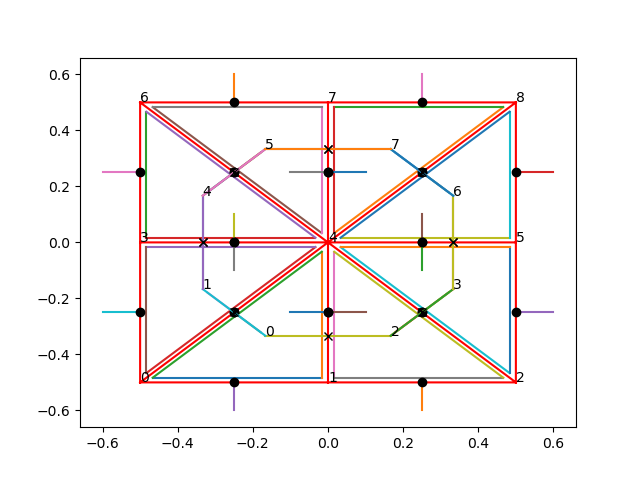

[0.5 0.5] [-0.25 -0.25]
(array([0.5, 0. ]), array([-0.25, -0.5 ]))


In [5]:
V, T = make_beam_mesh(1.0,1.0,(2,2))

info = MeshInfo(V,T)

fig = plt.figure()
plt.triplot(info.V[:,0],info.V[:,1],info.T,color='r')
for v in range(len(V)):
    print('vertex ',v , ' has triangle neighbors ',info.get_triangles_of_vertex(v))
    plt.text(info.V[v,0],info.V[v,1], str(v))
for t in range(len(T)):
    print('Triangle ',t , ' has triangle neighbors ',info.get_triangles_of_triangle(t))
    c = info.get_triangle_center(t)
    plt.text(c[0],c[1], str(t))
for v in range(len(V)):
    print('vertex ',v , ' has vertex neighbors ',info.get_vertices_of_vertex(v))
for t in range(len(T)):
    c = info.get_triangle_center(t)
    for e in range(3):
        u, m = info.get_edge_vector_of_triangle(t,e)
        v = m - 0.5*u
        w = m + 0.5*u
        m = (m-c)*0.9 + c
        v = (v-c)*0.9 + c
        w = (w-c)*0.9 + c
        plt.plot([v[0], w[0]], [v[1], w[1]] )
for t in range(len(T)):
    for e in range(3):
        n, m = info.get_outward_normal_of_triangle(t,e)
        plt.plot([m[0], 0.1*n[0]+m[0]], [m[1], 0.1*n[1]+m[1]] )
        plt.plot(m[0], m[1],'ko')
for t in range(len(T)):
    for e in range(3):
        u, m = info.get_triangle_triangle_segment(t,e)
        if not u is None: 
            v = m - 0.5*u
            w = m + 0.5*u
            plt.plot([v[0], w[0]], [v[1], w[1]] )
            plt.plot(m[0], m[1],'kx')
plt.show()    

res = info.get_edge_vector_of_triangle(0,2)
print(-res[0], res[1])
print(info.get_edge_vector_of_triangle(0,0))

# Creating Vertex-centered Control Volumes
We may now use the mesh information functionality to quickly generate a simple control volume data structure.

We will take a rather brute-force approach and simply create a chunk of vertex-related information that is very specific to the simulation method we will immplement here.

We will exploit one very smart trick here which is to make a cyclic permulation a local copy of neighboring triangles such that the first index of each triangle is the vertex that they all have in common.

This is cleaver later on at run-time as we have explicit knowledge of where the two other vertices of each triangle is located in the vertex neighborhood. Further, it enable us to deduce a CCW order of triangles around a vertex. Although in this example we have little use of this knowledge.

In [6]:
def get_cyclic_permuation(v, triangle):
    i = triangle[0]
    j = triangle[1]
    k = triangle[2]
    if i==v:
        return [i, j, k]
    if j==v:
        return [j, k, i]
    if k==v:
        return [k, i, j]
    return [-1, -1, -1]


def get_ccw_triangle_order(v, T):
    for t in range(len(T)):
        T[t,:] = get_cyclic_permuation(v, T[t,:])    
    if len(T) == 1:
        ccw_order = np.array([0], dtype=np.int32).flatten()
    else:
        ccw_order = []
        next_order = -np.ones( (len(T), ), dtype=np.int32 )
        prev_order = -np.ones( (len(T), ), dtype=np.int32 )
        for s in range(len(T)):
            A = T[s,:]
            for t in range(len(T)):
                B = T[t,:]
                if A[2]==B[1]:
                    next_order[s] = t
                if A[1]==B[2]:
                    prev_order[s] = t
        if np.any(prev_order<0):
            i = np.where(prev_order<0)[0]
            while i>=0:
                ccw_order.append(i)
                i = next_order[i]
        else:
            i = 0
            ccw_order.append(i)
            i = next_order[i]
            while i>0:
                ccw_order.append(i)
                i = next_order[i]            
        ccw_order = np.array(ccw_order, dtype=np.int32).flatten()
    return ccw_order
    
    
class VertexControlVolume:

    def __init__(self, v, info):
        self.v = v
        self.c = info.V[v,:].flatten()
        self.labels = info.get_triangles_of_vertex(v)
        K = len(self.labels)        
        self.K = K
        self.boundary = info.is_boundary_vertex(v)
        
        T = info.T[self.labels,:]
        for t in range(len(T)):
            T[t,:] = get_cyclic_permuation(v, T[t,:])    
        
        self.Lij = np.zeros(( K, ), dtype=np.float64 )
        self.Lik = np.zeros(( K, ), dtype=np.float64 )
        self.Nij = np.zeros(( K, 2), dtype=np.float64 )
        self.Nik = np.zeros(( K, 2), dtype=np.float64 )
        self.Sij = np.zeros(( K, 2), dtype=np.float64 )
        self.Sik = np.zeros(( K, 2), dtype=np.float64 )
        self.P = np.zeros(( K, 2), dtype=np.float64 )
        self.A = np.sum(info.A[self.labels])/3.0
        for e in range(K):
            i = T[e,0]
            j = T[e,1]
            k = T[e,2]
            
            pi = info.V[i,:]
            pj = info.V[j,:]
            pk = info.V[k,:]
            
            Eij = (pj-pi)
            Lij = np.linalg.norm(Eij)
            Nij = -hat(Eij)/Lij
            
            Eik = (pk-pi)
            Lik = np.linalg.norm(Eik)
            Nik = hat(Eik)/Lik
        
            self.Lij[e] = Lij/2
            self.Lik[e] = Lik/2
            self.Nij[e,:] = Nij
            self.Nik[e,:] = Nik
            self.Sij[e,:] = Eij/2
            self.Sik[e,:] = Eik/2
            self.P[e,:] = (pi+pj+pk)/3

Now we will do a little debug rendering to test if the information in the new control volume is created correctly.

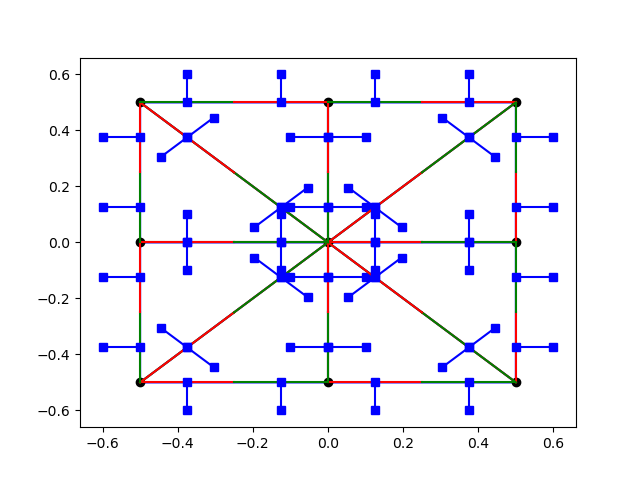

In [7]:
info = MeshInfo(V,T)

CVs = []
for v in range(len(V)):
    cv = VertexControlVolume(v,info)
    CVs.append(cv)            

fig = plt.figure()
plt.triplot(info.V[:,0],info.V[:,1],info.T,color='b')
for v in range(len(info.V)):
    cv = CVs[v]
    plt.plot(cv.c[0],cv.c[1],'ko')
    
    for e in range(cv.K):
        start = cv.c
        end = cv.c + cv.Sij[e]
        plt.plot([start[0], end[0]],[start[1], end[1]],'-r')
                   
        start = cv.c
        end = cv.c + cv.Sik[e]
        plt.plot([start[0], end[0]],[start[1], end[1]],'-g')

        start = cv.c+cv.Sij[e]/2
        end = cv.c+cv.Sij[e]/2 + cv.Nij[e]*0.1
        plt.plot([start[0], end[0]],[start[1], end[1]],'-bs')
                   
        start = cv.c+cv.Sik[e]/2
        end = cv.c+cv.Sik[e]/2 + cv.Nik[e]*0.1
        plt.plot([start[0], end[0]],[start[1], end[1]],'-bs')
plt.show()    

Next will will render the control volume shapes so we can see how they look like. They have a very specific shape and it is easy to verify by visual inspection if they have been created correctly.

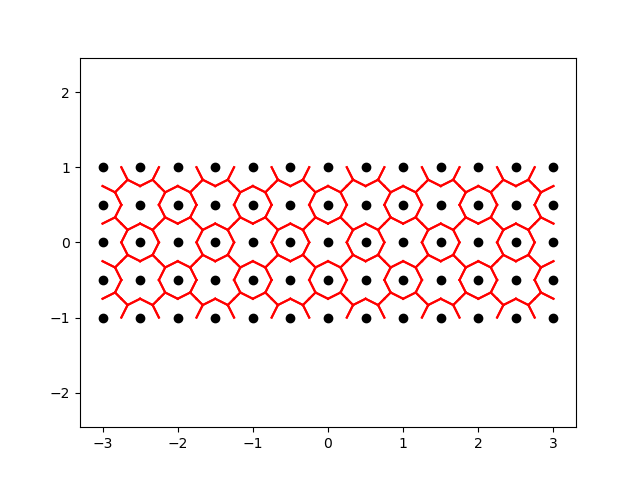

In [8]:
width = 6.0
height = 2.0
V, T = make_beam_mesh(width, height,(12,4)) # originally 6x2
# V, T = make_circle_mesh(0.75, 36)

info = MeshInfo(V,T)

CVs = []
for v in range(len(V)):
    cv = VertexControlVolume(v,info)
    CVs.append(cv)

fig = plt.figure()
ax = plt.subplot(111)
for v in range(len(CVs)):
    cv = CVs[v]
    plt.plot(cv.c[0],cv.c[1],'ko')
    for e in range(cv.K):
        start = cv.c + cv.Sij[e]
        end = cv.P[e]
        plt.plot([start[0], end[0]],[start[1], end[1]],'-r')
        start = cv.c + cv.Sik[e]
        end = cv.P[e]
        plt.plot([start[0], end[0]],[start[1], end[1]],'-r')
ax.axis('equal')
plt.show()

# Creating a 2D Hyperelastic Simualtor

This is your task to implement this...

Current implementation problems: 
- Not handling boundary edges
- 

In [9]:
# define material properties 
library = {
    'cartilage':(0.69e6, 0.018, 1000),
    'cortical bone': (16.16e9, 0.33, 1600),
    'cancellous bone': (452e6, 0.3, 1600),
    'rubber': (0.01e9, 0.48, 1050),
    'concrete': (30e9, 0.20, 2320),
    'copper': (125e9, 0.35, 8900),
    'steel': (210e9, 0.31, 7800),
    'aluminium': (72e9, 0.34, 2700),
    'glass': ( 50e9,  0.18, 2190),
}

In [10]:
frameStep = 0.05

class Simulator:
    
    def __init__(self, meshInfo, CVs, traction, bodyForce, materialName, dt, T):
        self.numCV = len(meshInfo.V) # number of control volumes 
        self.numT = len(meshInfo.T) # number of triangles 
        
        self.info = meshInfo
        self.CVs = CVs
        self.traction = traction
        self.bodyForce = bodyForce
        self.netForce = np.empty(traction.shape)
        
        # physical constants
        self.set_material(materialName)

        # simulation quantities
        self.tSteps = int(T / dt) # number of time steps over which the simulation is iterated
        self.frameSteps = int(T / frameStep) + 1 # number of frames saved
        self.stepNum = 0
        self.dt = dt 
        self.x = np.copy(meshInfo.V.T) # initialise spatial coordinates 
        self.v = np.zeros((2, self.numCV))
        self.xSaved = np.zeros((self.frameSteps, 2, self.numCV))
        self.xSaved[0,:,:] = np.copy(self.x)

        # deformations (store D inverse to save time)
        self.D = np.zeros((self.numT, 2, 2))
        self._compute_edge_vector_matrices()
        self.D0Inv = np.linalg.inv(self.D)        

        # save in memory to accelerate future computations
        self.tempI_ = np.tile(np.eye(2), [self.numT, 1, 1])

    def set_material(self, name):
        E, nu, rho = library[name]
        self.rho = rho

        # calculate Lame constants 
        self.l = (E * nu) / ((1 + nu) * (1 - 2*nu))
        self.mu = E / (2 * (1 + nu))

        # update control volume masses
        self._set_masses_and_areas()
        
        return

    # T: runtime of the simulation
    def run_simulation(self, scenario):   
        left_boundary_idxs = np.where( info.V[:,0] < -width/2 + 0.1 )[0]
        
        # iterate over time steps
        frameNum = 1
        for stepNum in range(1, self.tSteps): 
            self.stepNum = stepNum
            self._compute_net_force()
            
            # update velocity, position
            self.v += self.dt * (self.netForce / self.m)
            self.x += self.dt * self.v

            # apply boundary condition
            if scenario == 'cantilever': 
                self.x[:,left_boundary_idxs] = self.xSaved[0,:,left_boundary_idxs].T 
            elif scenario == 'bounce':
                groundLevel = -10
                undergroundMask = np.logical_and(self.x[1,:] < groundLevel, self.v[1,:] < 0)
                self.v[1, undergroundMask] *= -1
            else: 
                print('Scenario not recognised.')
                break

            # save frame
            if stepNum * self.dt >= frameNum * frameStep: 
                self.xSaved[frameNum,:,:] = np.copy(self.x)
                print(f'Frame at t = {frameNum * frameStep:0.2f} saved')
                
                frameNum += 1                

            # plt.figure(99, figsize=(5,3))
            # plt.triplot(self.x[0,:], self.x[1,:], self.info.T)
            # plt.quiver(self.x[stepNum-1,0,:], self.x[stepNum-1,1,:], self.v[0,:], self.v[1,:], width=5e-3)
            # plt.quiver(self.x[stepNum-1,0,:], self.x[stepNum-1,1,:], self.netForce[0,:], self.netForce[1,:], width=5e-3)            
            # plt.show()

        print('Simulation complete.')
        
        return

    # calculate the mass and area of each control volume
    def _set_masses_and_areas(self):
        self.m = np.empty((self.numCV,)) 
        self.A = np.empty((self.numCV,))
        
        for cvNum in range(self.numCV):
            self.m[cvNum] = self.rho * self.CVs[cvNum].A
            self.A[cvNum] = self.CVs[cvNum].A
        
        return 

    # calculate the force acting on each control volume 
    def _compute_net_force(self):
        elasticForce = np.zeros((2, self.numCV)) # elastic forces acting on each control volume 
        P = self._get_stress_tensors()
        
        # calculate the elastic forces acting on each control volume
        for cvNum in range(self.numCV):
            cv = self.CVs[cvNum]
            
            # sum the elastic forces across each triangle in the control volume
            elasticForce[:,cvNum] += np.sum(np.einsum('Bnm,Bm -> nB', P[cv.labels,:,:], cv.Nij) * cv.Lij, axis=1)
            elasticForce[:,cvNum] += np.sum(np.einsum('Bnm,Bm -> nB', P[cv.labels,:,:], cv.Nik) * cv.Lik, axis=1)

            # for e in range(cv.K):
            #     triNum = cv.labels[e]
                
                # elasticForce[:,cvNum] += np.dot(P[triNum,:,:], cv.Nij[e,:]) * cv.Lij[e]
            #     elasticForce[:,cvNum] += np.dot(P[triNum,:,:], cv.Nik[e,:]) * cv.Lik[e]
        
            # handle boundary conditions 
            # if cv.boundary and len(cv.labels) == 2: 
            #     elasticForce[:,cvNum] *= 1.5
            # elif cv.boundary and len(cv.labels) == 4: 
            #     elasticForce[:,cvNum] *= 1.25

        # calculate total force on each control volume
        self.netForce = self.A * (self.bodyForce + self.traction) - elasticForce

        return

    # compute the P matrix for all triangles at the current time step 
    def _get_stress_tensors(self):
        self._compute_edge_vector_matrices()

        # calculate deformation for each triangle
        F = np.matmul(self.D, self.D0Inv)
        E = 0.5 * ( np.matmul(np.transpose(F, axes=(0,2,1)), F) - self.tempI_ )
        E_trace = np.trace(E, axis1=1, axis2=2)
        S = self.l * np.reshape(E_trace, [-1,1,1]) * self.tempI_ + 2 * self.mu * E
        P = np.matmul(F, S)
        
        return P

    # compute the D matrix at the current time step 
    def _compute_edge_vector_matrices(self):
        i = self.info.T[:,0]
        j = self.info.T[:,1]
        k = self.info.T[:,2]
        vi = self.x[:,i]
        vj = self.x[:,j]
        vk = self.x[:,k]
        
        uij = vj - vi
        uik = vk - vi
        self.D[:,:,0] = uij.T
        self.D[:,:,1] = uik.T

        return

    # compute edge vectors (dx) of all triangles at the time step tStep
    # def _compute_edge_vector_matrices(self):
    #     V = self.x.T
    #     currentMesh = MeshInfo(V, self.info.T)
        
    #     for tNum in range(self.numT):
    #         self.D[tNum,:,0] =  currentMesh.get_edge_vector_of_triangle(tNum, 0)[0]
    #         self.D[tNum,:,1] = -currentMesh.get_edge_vector_of_triangle(tNum, 2)[0]

    #     return 

    # def get_edge_vector_of_triangle(self, t, e):
    #     i = self.T[t,e]
    #     j = self.T[t,(e+1)%3]
    #     vi = self.V[i,:].flatten()
    #     vj = self.V[j,:].flatten()
    #     u = (vj-vi).flatten()
    #     return u, (vi+vj)/2

In [11]:
# set simulation time
dt = 1e-3
runtime = 15
material = 'rubber'

# set forces
traction = np.zeros((2, len(info.V)))
right_indices = np.array(np.where( V[:,0] > width/2 - 0.1 ), dtype=np.int32)
traction[1,right_indices] = -1e2

bodyForce = np.zeros((2, len(info.V)))
# for idx in range(len(info.V)): 
#     bodyForce[1,idx] = -9.81 * CVs[idx].A * library[material][2]

simulator = Simulator(info, CVs, traction, bodyForce, material, dt, runtime)
simulator.run_simulation('bounce')

Frame at t = 0.05 saved
Frame at t = 0.10 saved
Frame at t = 0.15 saved
Frame at t = 0.20 saved
Frame at t = 0.25 saved
Frame at t = 0.30 saved
Frame at t = 0.35 saved
Frame at t = 0.40 saved
Frame at t = 0.45 saved
Frame at t = 0.50 saved
Frame at t = 0.55 saved
Frame at t = 0.60 saved
Frame at t = 0.65 saved
Frame at t = 0.70 saved
Frame at t = 0.75 saved
Frame at t = 0.80 saved
Frame at t = 0.85 saved
Frame at t = 0.90 saved
Frame at t = 0.95 saved
Frame at t = 1.00 saved
Frame at t = 1.05 saved
Frame at t = 1.10 saved
Frame at t = 1.15 saved
Frame at t = 1.20 saved
Frame at t = 1.25 saved
Frame at t = 1.30 saved
Frame at t = 1.35 saved
Frame at t = 1.40 saved
Frame at t = 1.45 saved
Frame at t = 1.50 saved
Frame at t = 1.55 saved
Frame at t = 1.60 saved
Frame at t = 1.65 saved
Frame at t = 1.70 saved
Frame at t = 1.75 saved
Frame at t = 1.80 saved
Frame at t = 1.85 saved
Frame at t = 1.90 saved
Frame at t = 1.95 saved
Frame at t = 2.00 saved
Frame at t = 2.05 saved
Frame at t = 2.1

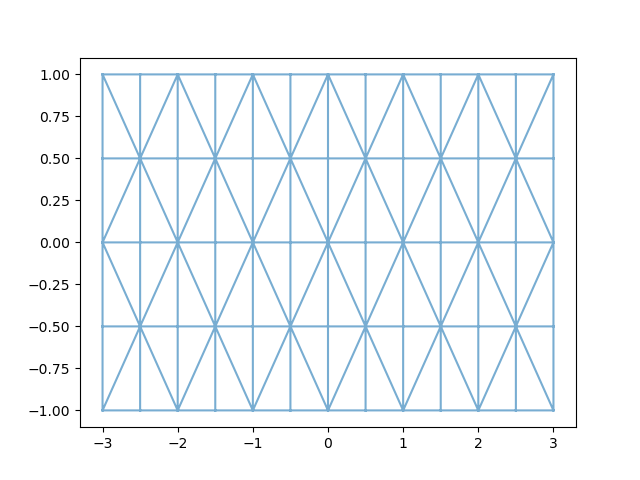

In [12]:
# plot final state 
tStep = -1
x = simulator.xSaved[tStep,0,:]
y = simulator.xSaved[tStep,1,:]

fig = plt.figure(98)
ax = plt.gca()
ax.cla()
ax.triplot(V[:,0], V[:,1], T, linewidth=1.5, alpha=0.6)
ax.triplot(x, y, T, linewidth=1, alpha=1)
plt.show()

Animation complete.


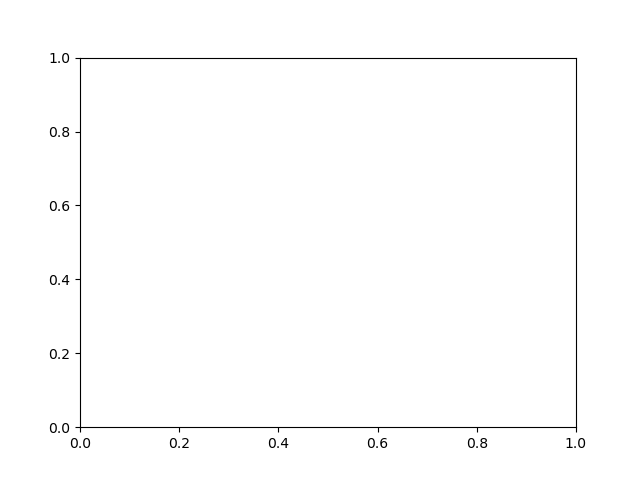

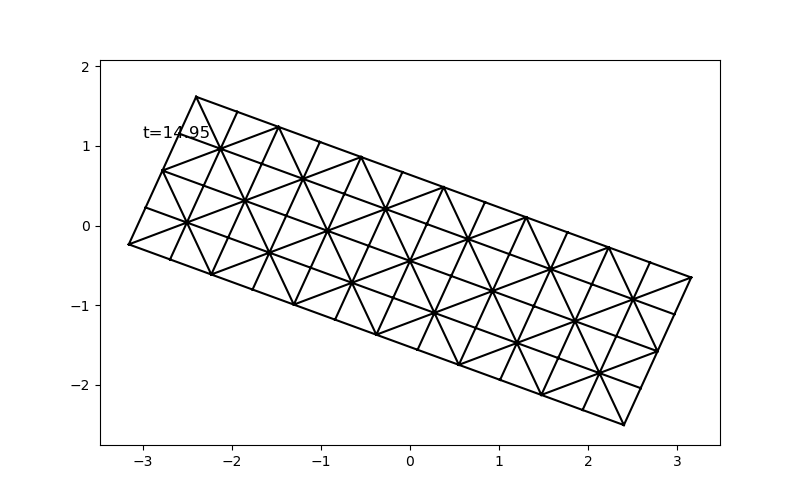

In [13]:
## animate gradual deformation 
figFake = plt.figure(96)
axFake = plt.gca()
mtp.rcParams['animation.embed_limit'] = 2**128

fig = plt.figure(97, figsize=(8,5))
ax = plt.gca()
ax.clear()
xMax = np.max(simulator.xSaved[:,0,:]) * 1.1
xMin = np.min(simulator.xSaved[:,0,:]) * 1.1
yMax = np.max(simulator.xSaved[:,1,:]) * 1.1 + 0.3
yMin = np.min(simulator.xSaved[:,1,:]) * 1.1
ax.set(xlim=[xMin, xMax], ylim=[yMin, yMax])
# ax.set_aspect('equal')

# plot initial state
x = simulator.xSaved[0,0,:]
y = simulator.xSaved[0,1,:]
triangles = tri.Triangulation(x, y, info.T)
line = ax.triplot(triangles, c='k', animated=True)[0]
text = ax.text(-3, 1.1, 't=0', fontsize=12)

def update_plot(tStep):   
    # get data for the frame
    x = simulator.xSaved[tStep,0,:]
    y = simulator.xSaved[tStep,1,:]

    # get triangle plotting data
    trianglesFake = tri.Triangulation(x, y, info.T) 
    lineFake, _ = axFake.triplot(trianglesFake, c='k')
    data = lineFake.get_data()
    axFake.clear()
    
    line.set_data(data)
    text.set_text(f't={tStep * frameStep:.2f}')
    
    return (line, text)

Nt = int(runtime / frameStep)
interval = frameStep * 1e3
frames = range(1, Nt)
ani = animation.FuncAnimation(fig=fig, func=update_plot, frames=frames, interval=interval, blit=True)
print('Animation complete.')


# print('Animation saved.')
HTML(ani.to_jshtml())

In [14]:
name = ''
ani.save(f'w7/{name}.mp4', writer='pillow')

ValueError: unknown file extension: 